# Prédiction du churn clients d'un opérateur télécom

**Objectif :** prédire quels clients risquent de quitter l'opérateur (variable `Churn`) afin de cibler des actions de rétention.

**Données :** dataset public *Telco Customer Churn* (IBM sample data, Kaggle) : 7 043 clients, 21 colonnes.
Lien : https://www.kaggle.com/datasets/blastchar/telco-customer-churn

**Démarche :** nettoyage → analyse exploratoire → préparation (encodage, split train/test) → modèles (régression logistique, random forest) → évaluation → variables influentes.

> Pour exécuter ce notebook dans Google Colab : cliquer sur *Exécution > Tout exécuter* et téléverser le fichier `WA_Fn-UseC_-Telco-Customer-Churn.csv` quand il est demandé.


## 1. Chargement des données

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt

FICHIER = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

# Dans Google Colab : téléversement du fichier s'il n'est pas déjà présent
if not os.path.exists(FICHIER):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Placer {FICHIER} dans le même dossier que ce notebook.")

df = pd.read_csv(FICHIER)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Exploration

In [4]:
df.info()
print()
print("Répartition de Churn :")
print(df["Churn"].value_counts(normalize=True).round(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Le jeu de données est **déséquilibré** : environ 73 % de clients restés contre 27 % de clients partis.
C'est pourquoi l'accuracy seule ne suffit pas pour évaluer les modèles (on regarde aussi le recall, la précision et l'AUC).

## 3. Nettoyage

- `TotalCharges` est lu comme du texte : conversion en nombre. 11 cases vides apparaissent. Elles concernent des clients avec `tenure = 0` (nouveaux abonnés pas encore facturés).
- Suppression de ces 11 lignes (0,16 % des données, impact négligeable).
- Suppression de `customerID` (identifiant sans valeur prédictive).
- `Churn` : No/Yes → 0/1.

In [5]:
# Vérification : les lignes sans TotalCharges ont-elles tenure = 0 ?
vides = df[df["TotalCharges"].str.strip() == ""]
print(len(vides), "lignes vides ; tenure =", vides["tenure"].unique())

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"]).drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print(df.shape)
print(df["Churn"].value_counts())

11 lignes vides ; tenure = [0]
(7032, 20)
Churn
0    5163
1    1869
Name: count, dtype: int64


## 4. Analyse exploratoire

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64

Contract
Month-to-month    3875
Two year          1685
One year          1472
Name: count, dtype: int64


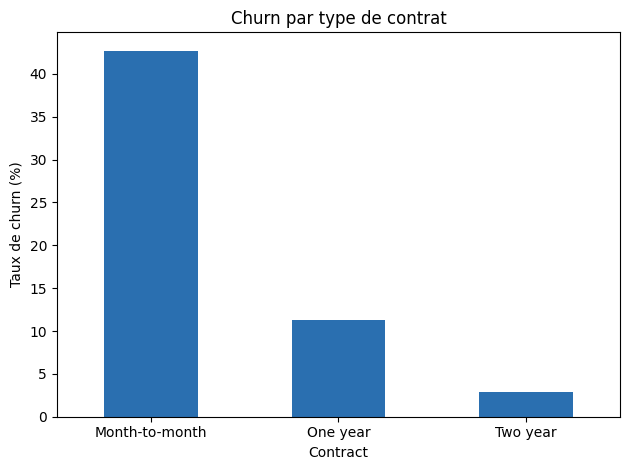

In [6]:
# Taux de churn par type de contrat
taux_contrat = df.groupby("Contract")["Churn"].mean() * 100
print(taux_contrat.round(1))
print()
print(df["Contract"].value_counts())

ax = taux_contrat.plot(kind="bar", color="#2a6fb0")
ax.set_ylabel("Taux de churn (%)")
ax.set_title("Churn par type de contrat")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

tenure
0-12     47.7
13-24    28.7
25-48    20.4
49-72     9.5
Name: Churn, dtype: float64


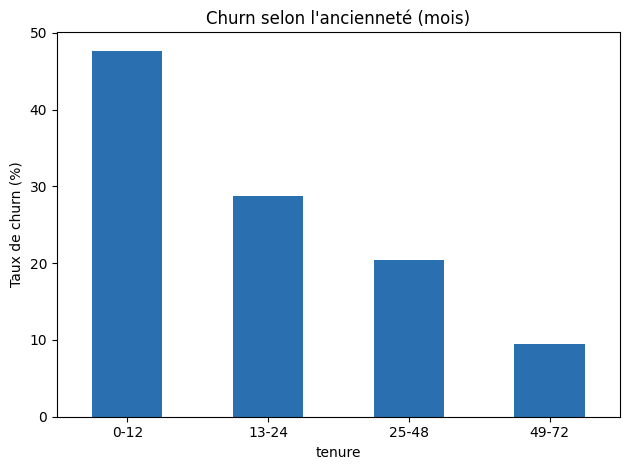

In [7]:
# Taux de churn selon l'ancienneté (en mois)
groupes = pd.cut(df["tenure"], bins=[0, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
taux_tenure = df.groupby(groupes, observed=True)["Churn"].mean() * 100
print(taux_tenure.round(1))

ax = taux_tenure.plot(kind="bar", color="#2a6fb0")
ax.set_ylabel("Taux de churn (%)")
ax.set_title("Churn selon l'ancienneté (mois)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Lecture :** le contrat mensuel concentre le risque de départ (environ 43 % de churn contre 11 % pour un contrat d'un an et 3 % pour deux ans).
Ce sont des **associations** observées dans les données, pas des relations de cause à effet.

## 5. Préparation des données

- `X` : variables d'entrée, `y` : cible (`Churn`).
- Encodage des colonnes texte en colonnes 0/1 (`get_dummies`).
- Séparation train (80 %) / test (20 %), avec `stratify=y` pour conserver la même proportion de churn dans les deux ensembles.

In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn"])
y = df["Churn"]

X = pd.get_dummies(X, drop_first=True)
print("X :", X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train :", X_train.shape, "| Test :", X_test.shape)
print("Taux de churn train / test :", y_train.mean().round(3), y_test.mean().round(3))

X : (7032, 30)
Train : (5625, 30) | Test : (1407, 30)
Taux de churn train / test : 0.266 0.266


## 6. Modèle 1 : régression logistique

Les variables sont mises à la même échelle (`StandardScaler`). Le scaler est ajusté sur le train uniquement, puis appliqué au test.

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_sc, y_train)

y_pred_lr = model_lr.predict(X_test_sc)
proba_lr = model_lr.predict_proba(X_test_sc)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred_lr), 3))
print("AUC      :", round(roc_auc_score(y_test, proba_lr), 3))
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Accuracy : 0.804
AUC      : 0.836
[[916 117]
 [159 215]]
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



## 7. Modèle 1 bis : régression logistique avec `class_weight="balanced"`

On pénalise davantage les erreurs sur les clients qui partent. Le recall augmente, la précision baisse : c'est un **compromis**, pas une amélioration du modèle.

In [10]:
model_bal = LogisticRegression(max_iter=1000, class_weight="balanced")
model_bal.fit(X_train_sc, y_train)

y_pred_bal = model_bal.predict(X_test_sc)
proba_bal = model_bal.predict_proba(X_test_sc)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred_bal), 3))
print("AUC      :", round(roc_auc_score(y_test, proba_bal), 3))
print(confusion_matrix(y_test, y_pred_bal))
print(classification_report(y_test, y_pred_bal))

Accuracy : 0.726
AUC      : 0.835
[[724 309]
 [ 76 298]]
              precision    recall  f1-score   support

           0       0.91      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



## 8. Modèle 2 : random forest

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
proba_rf = rf.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 3))
print("AUC      :", round(roc_auc_score(y_test, proba_rf), 3))
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Accuracy : 0.787
AUC      : 0.818
[[917 116]
 [184 190]]
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



## 9. Comparaison

L'AUC mesure la capacité du modèle à classer les clients du plus au moins risqué, indépendamment du seuil de décision.

In [12]:
resume = pd.DataFrame({
    "Modèle": ["Logistique", "Logistique (balanced)", "Random forest"],
    "Accuracy": [accuracy_score(y_test, p) for p in (y_pred_lr, y_pred_bal, y_pred_rf)],
    "AUC": [roc_auc_score(y_test, p) for p in (proba_lr, proba_bal, proba_rf)],
}).round(3)
resume

,Modèle,Accuracy,AUC
0,Logistique,0.804,0.836
1,Logistique (balanced),0.726,0.835
2,Random forest,0.787,0.818


**Choix retenu : la régression logistique.** Elle obtient les meilleurs résultats sur ce jeu de données et ses coefficients sont faciles à interpréter.
(Ces comparaisons reposent sur un seul découpage train/test et aucun réglage d'hyperparamètres n'a été effectué.)

## 10. Variables les plus influentes (régression logistique)

Coefficient positif : la variable est associée à un risque de départ plus élevé. Coefficient négatif : risque plus faible.

*Attention :* `tenure`, `MonthlyCharges` et `TotalCharges` sont corrélées entre elles ainsi qu'avec les services souscrits, donc leurs coefficients individuels sont à interpréter avec prudence.

=== Variables associées à un risque plus FAIBLE ===
tenure                             -1.35
MonthlyCharges                     -0.85
Contract_Two year                  -0.60
Contract_One year                  -0.31
OnlineSecurity_Yes                 -0.14
TechSupport_Yes                    -0.12
Dependents_Yes                     -0.11
OnlineBackup_No internet service   -0.09
dtype: float64

=== Variables associées à un risque plus ÉLEVÉ ===
SeniorCitizen                     0.07
PaperlessBilling_Yes              0.14
PaymentMethod_Electronic check    0.18
MultipleLines_Yes                 0.21
StreamingMovies_Yes               0.24
StreamingTV_Yes                   0.25
TotalCharges                      0.64
InternetService_Fiber optic       0.73
dtype: float64


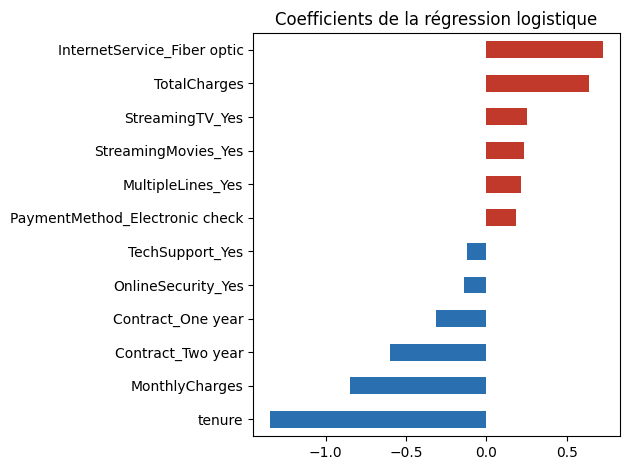

In [13]:
coef = pd.Series(model_lr.coef_[0], index=X.columns).sort_values()

print("=== Variables associées à un risque plus FAIBLE ===")
print(coef.head(8).round(2))
print("\n=== Variables associées à un risque plus ÉLEVÉ ===")
print(coef.tail(8).round(2))

top = pd.concat([coef.head(6), coef.tail(6)])
ax = top.plot(kind="barh", color=["#2a6fb0" if v < 0 else "#c0392b" for v in top])
ax.set_title("Coefficients de la régression logistique")
plt.tight_layout()
plt.show()

## 11. Conclusion et pistes

- Le **contrat mensuel**, une **faible ancienneté** et l'**internet fibre optique** sont associés à un risque de départ plus élevé ; un **contrat de 1 ou 2 ans** et une **forte ancienneté** à un risque plus faible.
- Le modèle ne donne pas de certitude : il produit une **probabilité de départ**, utilisable pour classer les clients et cibler des actions de rétention.
- Le choix du seuil dépend du coût d'une offre de rétention par rapport à la perte d'un client : un recall élevé est préférable si l'offre est peu coûteuse.

**Limites :** dataset public, un seul découpage train/test, pas de réglage d'hyperparamètres, associations non causales. Une suite possible : validation croisée, réglage des modèles, ajustement du seuil de décision, test A/B des offres.
